# **Title & Objective**

# 📈 Data Visualization & Final Report

## Objective

The objective of this notebook is to visualize the key findings from the Exploratory Data Analysis using Matplotlib and Seaborn.

The visualizations will help communicate sales, profit, product, category, regional, and time-based performance clearly.

---

## Visualization Areas

1. Category-wise Sales & Profit
2. Region-wise Sales & Profit
3. Year-wise Sales Trend
4. Year-wise Profit Trend
5. Monthly Sales Trend
6. Top 10 Products by Sales
7. Top 10 Products by Profit
8. Category-wise Quantity


----


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# **Load Dataset**

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
file_path = "/content/drive/MyDrive/Sales_Performance_Analytics/data/Superstore.csv"

df = pd.read_csv(file_path, encoding="latin1")

# **Prepare Required Columns**

In [ ]:
df['Order Date'] = pd.to_datetime(df['Order Date'])
df['Ship Date'] = pd.to_datetime(df['Ship Date'])

df['Order Year'] = df['Order Date'].dt.year
df['Order Month'] = df['Order Date'].dt.month
df['Order Month Name'] = df['Order Date'].dt.month_name()

# **Category-wise Sales & Profit**

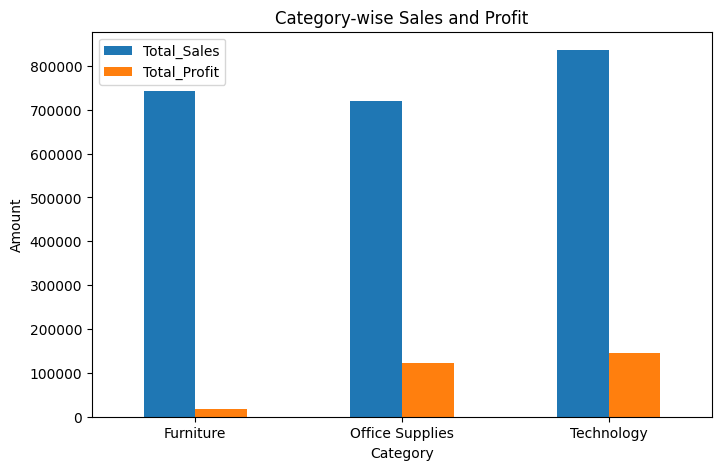

In [ ]:
category_summary = df.groupby('Category').agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum')
)

category_summary.plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('Category-wise Sales and Profit')
plt.xlabel('Category')
plt.ylabel('Amount')
plt.xticks(rotation=0)
plt.legend()

plt.savefig(
    "/content/drive/MyDrive/Sales_Performance_Analytics/charts/01_category_sales_profit.png",
    bbox_inches="tight"
)

plt.show()

## Category-wise Sales & Profit — Insight

- Technology recorded the highest total sales and profit among all categories.
- Office Supplies generated lower sales than Technology but achieved a strong profit.
- Furniture generated substantial sales but comparatively lower profit.

# **Region-wise Sales & Profit**

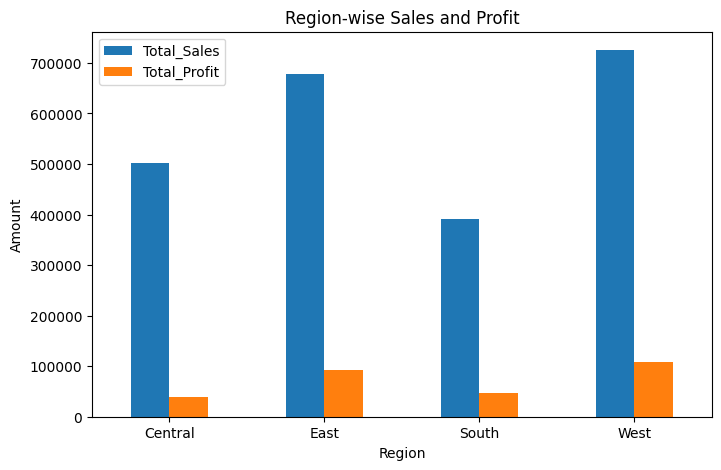

In [ ]:
region_summary = df.groupby('Region').agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum')
)

region_summary.plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('Region-wise Sales and Profit')
plt.xlabel('Region')
plt.ylabel('Amount')
plt.xticks(rotation=0)
plt.legend()

plt.savefig(
    "/content/drive/MyDrive/Sales_Performance_Analytics/charts/02_region_sales_profit.png",
    bbox_inches="tight"
)

plt.show()

## Region-wise Sales & Profit — Insight

- The West region recorded the highest total sales and profit.
- The East region recorded the second-highest sales and profit.
- The South region recorded the lowest total sales.
- The Central region generated higher sales than the South region but comparatively lower profit.

# **Year-wise Sales Trend**

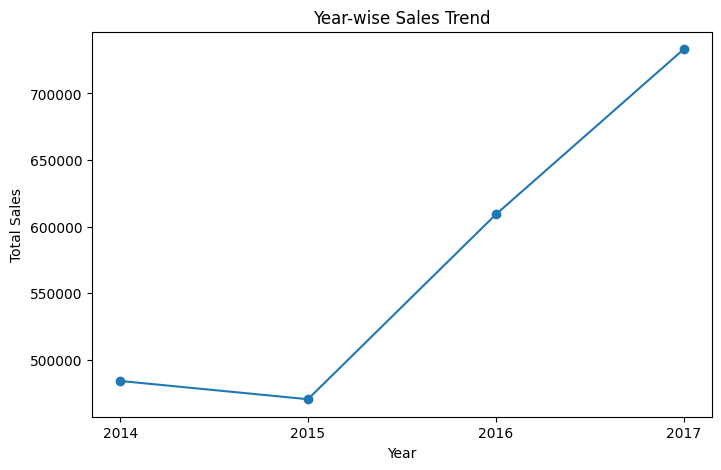

In [ ]:
yearly_sales = df.groupby('Order Year')['Sales'].sum()

plt.figure(figsize=(8, 5))

plt.plot(
    yearly_sales.index,
    yearly_sales.values,
    marker='o'
)

plt.title('Year-wise Sales Trend')
plt.xlabel('Year')
plt.ylabel('Total Sales')
plt.xticks(yearly_sales.index)

plt.savefig(
    "/content/drive/MyDrive/Sales_Performance_Analytics/charts/03_yearly_sales_trend.png",
    bbox_inches="tight"
)

plt.show()

## Year-wise Sales Trend — Insight

- Sales decreased slightly from 2014 to 2015.
- Sales increased significantly in 2016.
- 2017 recorded the highest total sales.
- The overall trend shows strong sales growth from 2015 to 2017.

# **Year-wise Profit Trend**

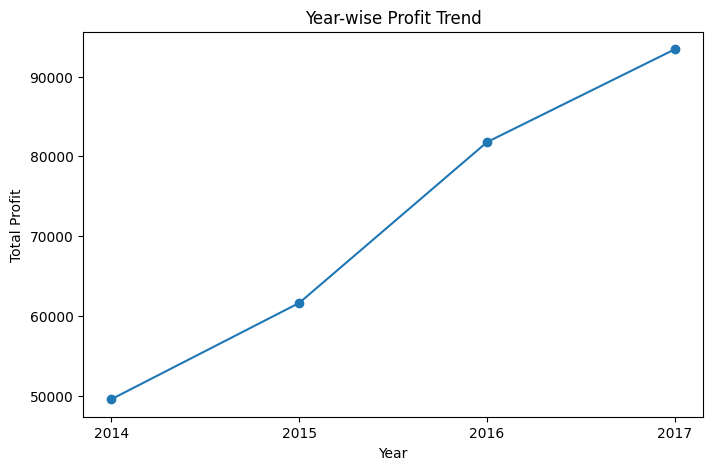

In [ ]:
yearly_profit = df.groupby('Order Year')['Profit'].sum()

plt.figure(figsize=(8, 5))

plt.plot(
    yearly_profit.index,
    yearly_profit.values,
    marker='o'
)

plt.title('Year-wise Profit Trend')
plt.xlabel('Year')
plt.ylabel('Total Profit')
plt.xticks(yearly_profit.index)

plt.savefig(
    "/content/drive/MyDrive/Sales_Performance_Analytics/charts/04_yearly_profit_trend.png",
    bbox_inches="tight"
)

plt.show()

## Year-wise Profit Trend — Insight

- Total profit increased consistently from 2014 to 2017.
- 2014 recorded the lowest total profit of 49,543.97.
- 2017 recorded the highest total profit of 93,439.27.
- The overall trend indicates continuous improvement in profitability during the analyzed period.

# **Monthly Sales Trend**

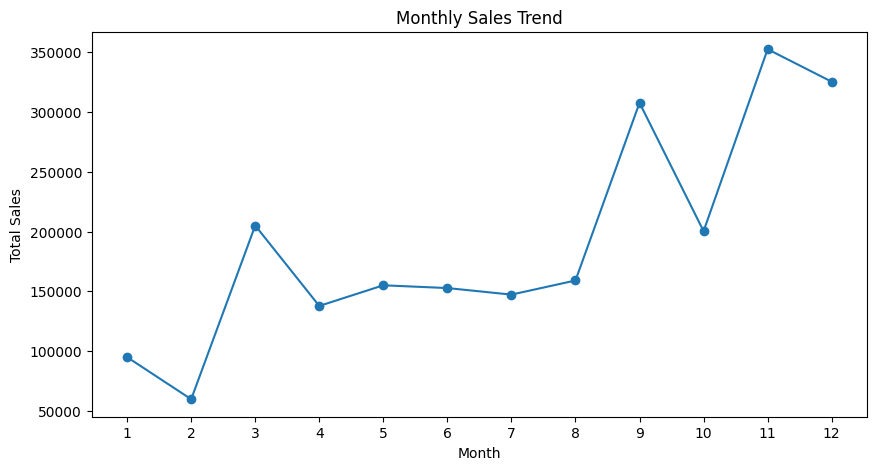

In [ ]:
monthly_sales = (
    df.groupby('Order Month')['Sales']
      .sum()
)

plt.figure(figsize=(10, 5))

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker='o'
)

plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(range(1, 13))

plt.savefig(
    "/content/drive/MyDrive/Sales_Performance_Analytics/charts/05_monthly_sales_trend.png",
    bbox_inches="tight"
)

plt.show()

## Monthly Sales Trend — Insight

- November recorded the highest monthly sales.
- February recorded the lowest monthly sales.
- Sales increased significantly in September.
- November and December recorded the strongest monthly sales performance.
- The monthly trend shows noticeable variation in sales throughout the year.

# **Top 10 Products by Sales**

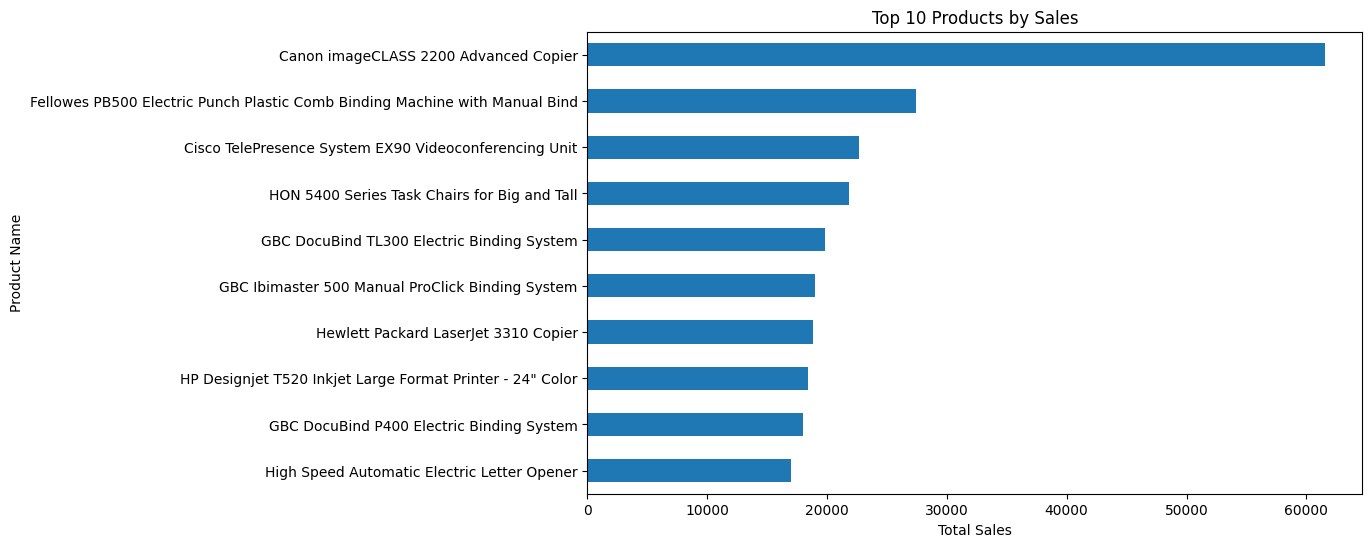

In [ ]:
top_products = (
    df.groupby('Product Name')['Sales']
      .sum()
      .sort_values(ascending=False)
      .head(10)
)

plt.figure(figsize=(10, 6))

top_products.sort_values().plot(
    kind='barh'
)

plt.title('Top 10 Products by Sales')
plt.xlabel('Total Sales')
plt.ylabel('Product Name')

plt.savefig(
    "/content/drive/MyDrive/Sales_Performance_Analytics/charts/06_top_10_products_sales.png",
    bbox_inches="tight"
)

plt.show()

## Top 10 Products by Sales — Insight

- Canon imageCLASS 2200 Advanced Copier recorded the highest total sales of 61,599.82.
- The sales of the top product are significantly higher than the other top-performing products.
- Copiers, printers, binding systems, and other office equipment appear prominently among the top-selling products.

# **Top 10 Products by Profit**

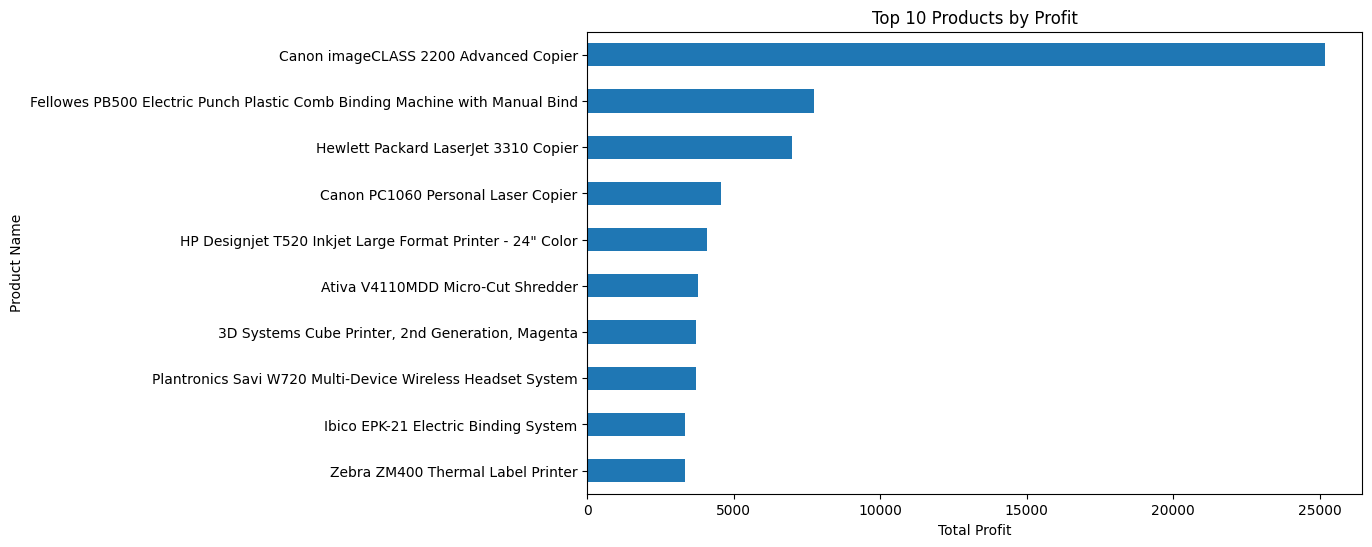

In [ ]:
top_profit_products = (
    df.groupby('Product Name')['Profit']
      .sum()
      .sort_values(ascending=False)
      .head(10)
)

plt.figure(figsize=(10, 6))

top_profit_products.sort_values().plot(
    kind='barh'
)

plt.title('Top 10 Products by Profit')
plt.xlabel('Total Profit')
plt.ylabel('Product Name')

plt.savefig(
    "/content/drive/MyDrive/Sales_Performance_Analytics/charts/07_top_10_products_profit.png",
    bbox_inches="tight"
)

plt.show()

## Top 10 Products by Profit — Insight

- Canon imageCLASS 2200 Advanced Copier recorded the highest total profit of 25,199.93.
- The top product generated significantly higher profit than the other top-performing products.
- Copiers, printers, binding systems, and other office equipment appear prominently among the top profitable products.

# **Category-wise Quantity**

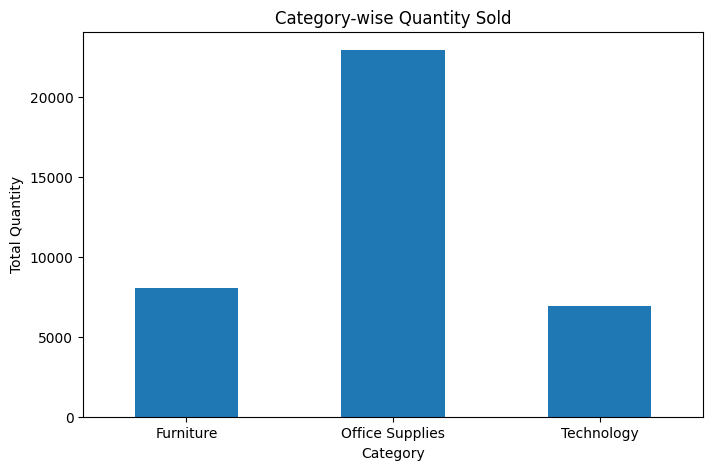

In [ ]:
category_quantity = df.groupby('Category')['Quantity'].sum()

plt.figure(figsize=(8, 5))

category_quantity.plot(
    kind='bar'
)

plt.title('Category-wise Quantity Sold')
plt.xlabel('Category')
plt.ylabel('Total Quantity')
plt.xticks(rotation=0)

plt.savefig(
    "/content/drive/MyDrive/Sales_Performance_Analytics/charts/08_category_quantity.png",
    bbox_inches="tight"
)

plt.show()

## Category-wise Quantity Sold — Insight

- Office Supplies recorded the highest quantity sold with 22,906 units.
- Furniture recorded 8,028 units sold.
- Technology recorded 6,939 units sold.
- Although Office Supplies had the highest quantity sold, Technology generated the highest sales and profit.
- This shows that sales performance depends not only on the quantity sold but also on the value of products.

# **Key Business Insights**

# 🔎 Key Business Insights

## Sales & Profit Performance

- Total sales generated by the dataset were 2,297,200.86.
- Total profit generated was 286,397.02.
- Technology was the highest-performing category in terms of both sales and profit.
- The West region recorded the highest sales and profit.
- 2017 recorded the highest annual sales and profit.

---

## Product Performance

- Canon imageCLASS 2200 Advanced Copier was the top product by sales.
- Canon imageCLASS 2200 Advanced Copier also generated the highest total profit.
- Copiers, printers, binding systems, and other office equipment appeared prominently among the top-performing products.

---

## Customer Performance

- Sean Miller was the highest-sales customer among the analyzed customers.

---

## Quantity Performance

- Office Supplies recorded the highest quantity sold with 22,906 units.
- Technology generated higher sales and profit despite having a lower quantity sold than Office Supplies.

---

## Time-Based Performance

- Sales increased strongly from 2015 to 2017.
- Profit increased consistently from 2014 to 2017.
- November recorded the highest monthly sales.
- February recorded the lowest monthly sales.

# **Business Recommendations**

# 💡 Business Recommendations

Based on the analysis, the following recommendations can be considered:

1. Focus on Technology products because the category generated the highest sales and profit.

2. Maintain strong business operations in the West region because it recorded the highest sales and profit.

3. Monitor Furniture performance because it generated substantial sales but comparatively lower profit.

4. Give attention to high-performing products such as the Canon imageCLASS 2200 Advanced Copier.

5. Use the monthly sales trend to plan inventory and marketing activities, especially during high-sales months.

6. Identify and maintain relationships with high-value customers who contribute significantly to sales.

7. Further investigate why Office Supplies has the highest quantity sold while Technology generates higher sales and profit.

# **Final Conclusion**

# 🎯 Final Conclusion

The Sales Performance Analytics project demonstrated an end-to-end Python-based data analysis workflow.

The project started with raw Superstore sales data and covered data loading, inspection, cleaning, transformation, exploratory data analysis, and visualization.

Using Pandas and NumPy, the dataset was cleaned and transformed into an analysis-ready format. Different analytical techniques such as filtering, grouping, aggregation, sorting, and time-based analysis were used to identify important patterns.

Matplotlib and Seaborn were used to visualize the major findings.

The analysis identified Technology as the strongest category, West as the highest-performing region, 2017 as the strongest year, and the Canon imageCLASS 2200 Advanced Copier as a leading product in both sales and profit.

Overall, the project demonstrates how Python can be used to transform raw sales data into meaningful business insights and support data-driven decision making.